In [16]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Chargement avec chemins relatifs
df_rte = pd.read_csv("../data/df_rte.csv")
df_meteo = pd.read_csv("../data/df_meteo.csv")

print("=== RTE ===")
print(df_rte.info())
print(df_rte.head(2))

print("\n=== METEO ===")
print(df_meteo.info())
print(df_meteo.head(2))

=== RTE ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 210408 entries, 0 to 210407
Data columns (total 9 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   date_heure_utc        210408 non-null  object 
 1   consommation          105203 non-null  float64
 2   solaire               105203 non-null  float64
 3   eolien                105203 non-null  float64
 4   nucleaire             105203 non-null  float64
 5   hydraulique           105203 non-null  float64
 6   gaz                   105203 non-null  float64
 7   ech_physiques         105203 non-null  float64
 8   charge_residuelle_mw  105203 non-null  float64
dtypes: float64(8), object(1)
memory usage: 14.4+ MB
None
              date_heure_utc  consommation  solaire  eolien  nucleaire  \
0  2020-01-01 00:00:00+00:00       63943.0     -1.0  3203.0    48970.0   
1  2020-01-01 00:15:00+00:00           NaN      NaN     NaN        NaN   

   hydraulique     gaz  e

### Ce qu’on voit
RTE contient 105 203 mesures électriques. Open-Meteo en fournit 157 824 pour Brest, Marseille et Paris.

### Pourquoi
RTE décrit le système électrique national. Les trois villes ne couvrent pas toute la météo française.

### Lien avec la question
Ces données permettent de comparer météo, production et consommation, avec une couverture géographique limitée.

In [17]:
# 1. Voir quelles sont les villes présentes dans df_meteo
print("Villes dans le dataset météo :", df_meteo["ville"].unique())

# 2. Nettoyage et agrégation de df_rte : moyenne des 2 observations (xx:00 et xx:30) par heure
df_rte_clean = df_rte.dropna(subset=["consommation"]).copy()
df_rte_clean["date_heure_utc"] = pd.to_datetime(df_rte_clean["date_heure_utc"]).dt.floor("h")
df_rte_horaire = (
    df_rte_clean.groupby("date_heure_utc", as_index=False)
    .mean(numeric_only=True)
)

# 2.1 Correction de la production solaire et recalcul de la charge résiduelle horaire
df_rte_horaire["solaire"] = df_rte_horaire["solaire"].clip(lower=0)
df_rte_horaire["charge_residuelle_mw"] = (
    df_rte_horaire["consommation"]
    - df_rte_horaire["eolien"]
    - df_rte_horaire["solaire"]
)

# 3. Agrégation de df_meteo : moyenne météorologique des trois villes par heure
df_meteo["date_heure_utc"] = pd.to_datetime(df_meteo["date_heure_utc"])
df_meteo_nat = (
    df_meteo.groupby("date_heure_utc", as_index=False)[
        ["wind_speed_100m", "shortwave_radiation", "temperature_2m"]
    ]
    .mean()
)

# 4. Jointure (merge) des deux tables sur la colonne date_heure_utc
df = pd.merge(df_rte_horaire, df_meteo_nat, on="date_heure_utc", how="inner")

# 5. Petit nettoyage final et création de variables utiles
df["enr_total"] = df["solaire"] + df["eolien"]
df["part_enr"] = (df["enr_total"] / df["consommation"]) * 100

# Vérification du résultat
print(f"Nombre d'heures après fusion : {len(df)}")
print(f"Période couverte : du {df['date_heure_utc'].min()} au {df['date_heure_utc'].max()}")
display(df.head(3))

Villes dans le dataset météo : ['Brest' 'Marseille' 'Paris']
Nombre d'heures après fusion : 52602
Période couverte : du 2020-01-01 00:00:00+00:00 au 2025-12-31 23:00:00+00:00


,date_heure_utc,consommation,solaire,eolien,nucleaire,hydraulique,gaz,ech_physiques,charge_residuelle_mw,wind_speed_100m,shortwave_radiation,temperature_2m,enr_total,part_enr
0,2020-01-01 00:00:00+00:00,63923.5,0.0,3092.0,49309.0,9128.5,5943.5,-4812.5,60831.5,1.380000,0.0,4.900000,3092.0,4.837032
1,2020-01-01 01:00:00+00:00,63059.5,0.0,2781.0,49755.5,8455.5,4916.0,-4107.5,60278.5,1.523333,0.0,4.833333,2781.0,4.410121
2,2020-01-01 02:00:00+00:00,60078.5,0.0,2816.0,49707.0,7496.5,3301.0,-3780.5,57262.5,2.000000,0.0,4.600000,2816.0,4.687201


### Ce qu’on voit
La fusion couvre 52 602 heures, de 2020 à 2025. Les valeurs sont ramenées à l’heure.

### Pourquoi
Cette mise au même pas de temps permet de rapprocher météo et données électriques. La charge résiduelle est calculée comme la consommation moins l’éolien et le solaire.

### Lien avec la question
On peut observer leurs variations conjointes, mais la moyenne de trois villes et l’agrégation horaire simplifient la réalité.

In [18]:
# STATISTIQUES DESCRIPTIVES
cols_meteo = ["wind_speed_100m", "shortwave_radiation", "temperature_2m"]
cols_elec = ["consommation", "solaire", "eolien", "enr_total", "nucleaire", "gaz", "charge_residuelle_mw"]

print("=== STATISTIQUES DESCRIPTIVES (MOYENNES, ÉCARTS-TYPES, QUARTILES) ===")
display(df[cols_meteo + cols_elec].describe().round(1))

=== STATISTIQUES DESCRIPTIVES (MOYENNES, ÉCARTS-TYPES, QUARTILES) ===


,wind_speed_100m,shortwave_radiation,temperature_2m,consommation,solaire,eolien,enr_total,nucleaire,gaz,charge_residuelle_mw
count,52602.0,52602.0,52602.0,52602.0,52602.0,52602.0,52602.0,52602.0,52602.0,52602.0
mean,6.6,159.9,14.1,51035.8,2354.8,4989.7,7344.5,38577.5,3310.6,43691.3
std,2.5,226.5,6.1,10918.1,3575.7,3853.5,4820.5,7306.9,2520.0,11226.3
min,0.8,0.0,-1.5,29364.5,0.0,46.5,61.0,19231.0,198.0,14769.5
25%,4.8,0.0,9.5,42957.2,0.0,2024.6,3397.0,33277.4,1067.5,35450.0
50%,6.4,12.3,13.6,49256.8,81.5,3823.0,6407.0,39171.5,2828.2,41434.0
75%,8.2,271.7,18.5,58211.4,3967.9,7060.4,10359.4,43352.4,4854.0,50324.5
max,20.9,915.0,35.8,87864.5,21543.5,20046.0,29417.5,56312.0,10565.0,85356.0


### Ce qu’on voit
La consommation moyenne est de 51,0 GW, contre 5,0 GW d’éolien et 2,35 GW de solaire. La charge résiduelle moyenne atteint 43,7 GW.

### Pourquoi
La production solaire varie avec le jour et les saisons. La demande dépend aussi des besoins de chauffage.

### Lien avec la question
Ces moyennes donnent un ordre de grandeur du poids des EnR face à la demande. Elles ne mesurent pas un effet causal.

In [19]:
print("=== MATRICE DE CORRÉLATION (MÉTÉO vs PRODUCTION / CONSOMMATION) ===")
corr_matrix = df[cols_meteo + cols_elec].corr().loc[cols_meteo, cols_elec]
display(corr_matrix.round(3))

=== MATRICE DE CORRÉLATION (MÉTÉO vs PRODUCTION / CONSOMMATION) ===


,consommation,solaire,eolien,enr_total,nucleaire,gaz,charge_residuelle_mw
wind_speed_100m,0.188,-0.182,0.796,0.501,0.097,-0.010,-0.032
shortwave_radiation,-0.056,0.868,-0.189,0.492,-0.297,-0.207,-0.266
temperature_2m,-0.597,0.491,-0.244,0.169,-0.587,-0.495,-0.653


### Ce qu’on voit
Le rayonnement est fortement lié au solaire (r = 0,868), et le vent à l’éolien (r = 0,796). La température est liée négativement à la consommation (r = −0,597).

### Pourquoi
Le soleil et le vent alimentent les filières correspondantes. Le froid augmente souvent le chauffage électrique.

### Lien avec la question
Ces liens vont dans le sens attendu, mais corrélation ne signifie pas causalité. La météo ne représente que trois villes.

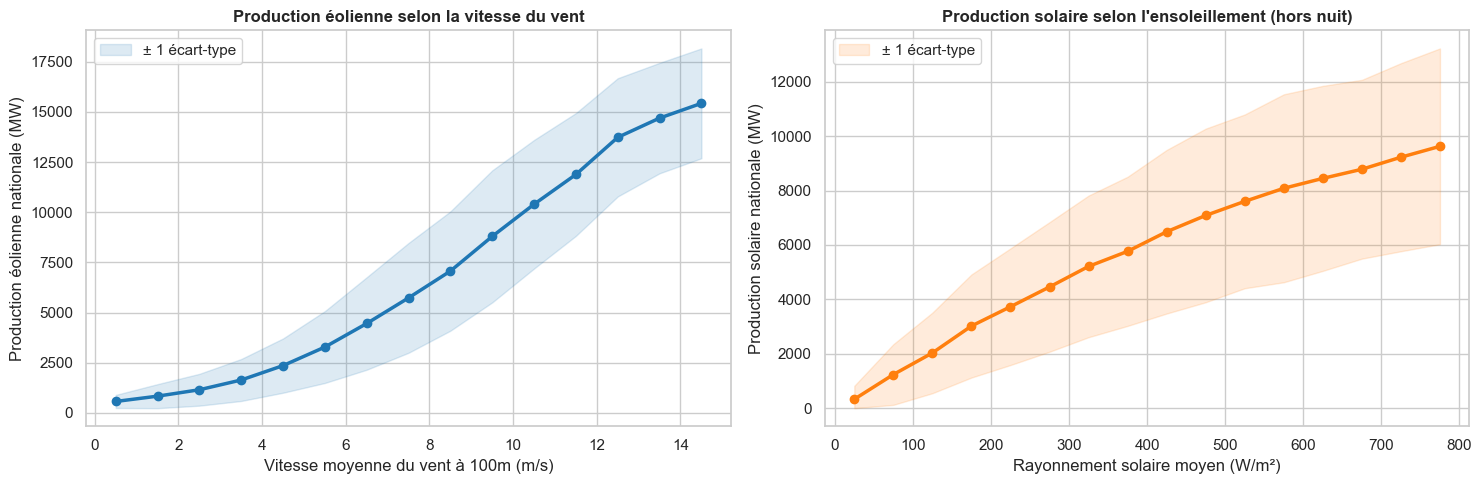

In [20]:
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# 1A. Vent -> Production Éolienne
df["bin_vent"] = pd.cut(df["wind_speed_100m"], bins=np.arange(0, 16, 1))
vent_profil = df.groupby("bin_vent", observed=True)["eolien"].agg(["mean", "std"]).reset_index()
vent_profil["vent_milieu"] = vent_profil["bin_vent"].apply(lambda x: x.mid).astype(float)

axes[0].plot(vent_profil["vent_milieu"], vent_profil["mean"], marker="o", color="#1f77b4", linewidth=2.5)
axes[0].fill_between(
    vent_profil["vent_milieu"],
    (vent_profil["mean"] - vent_profil["std"]).clip(lower=0),
    vent_profil["mean"] + vent_profil["std"],
    color="#1f77b4", alpha=0.15, label="± 1 écart-type"
)
axes[0].set_title("Production éolienne selon la vitesse du vent", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Vitesse moyenne du vent à 100m (m/s)")
axes[0].set_ylabel("Production éolienne nationale (MW)")
axes[0].legend()

# 1B. Rayonnement -> Production Solaire (hors nuit)
df_jour = df[df["shortwave_radiation"] > 0].copy()
df_jour["bin_rad"] = pd.cut(df_jour["shortwave_radiation"], bins=np.arange(0, 850, 50))
sol_profil = df_jour.groupby("bin_rad", observed=True)["solaire"].agg(["mean", "std"]).reset_index()
sol_profil["rad_milieu"] = sol_profil["bin_rad"].apply(lambda x: x.mid).astype(float)

axes[1].plot(sol_profil["rad_milieu"], sol_profil["mean"], marker="o", color="#ff7f0e", linewidth=2.5)
axes[1].fill_between(
    sol_profil["rad_milieu"],
    (sol_profil["mean"] - sol_profil["std"]).clip(lower=0),
    sol_profil["mean"] + sol_profil["std"],
    color="#ff7f0e", alpha=0.15, label="± 1 écart-type"
)
axes[1].set_title("Production solaire selon l'ensoleillement (hors nuit)", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Rayonnement solaire moyen (W/m²)")
axes[1].set_ylabel("Production solaire nationale (MW)")
axes[1].legend()

plt.tight_layout()
plt.show()

### Ce qu’on voit
La production éolienne moyenne dépasse 15 GW dans les classes de vent les plus fortes. La production solaire approche 9,6 GW aux rayonnements les plus élevés.

### Pourquoi
Le vent et le rayonnement favorisent respectivement l’éolien et le solaire.

### Lien avec la question
Les profils relient météo et production EnR, sans isoler les autres facteurs. La météo est une moyenne de trois villes.

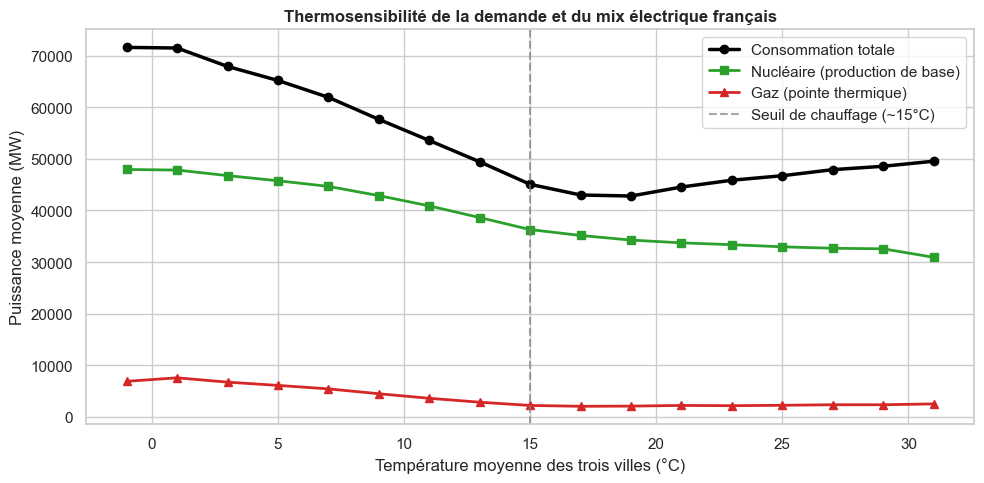

In [21]:
fig, ax = plt.subplots(figsize=(10, 5))

df["bin_temp"] = pd.cut(df["temperature_2m"], bins=np.arange(-4, 34, 2))
temp_profil = df.groupby("bin_temp", observed=True)[["consommation", "nucleaire", "gaz"]].mean().reset_index()
temp_profil["temp_milieu"] = temp_profil["bin_temp"].apply(lambda x: x.mid).astype(float)

ax.plot(temp_profil["temp_milieu"], temp_profil["consommation"], marker="o", label="Consommation totale", color="black", linewidth=2.5)
ax.plot(temp_profil["temp_milieu"], temp_profil["nucleaire"], marker="s", label="Nucléaire (production de base)", color="#2ca02c", linewidth=2)
ax.plot(temp_profil["temp_milieu"], temp_profil["gaz"], marker="^", label="Gaz (pointe thermique)", color="#d62728", linewidth=2)
ax.axvline(15, color="gray", linestyle="--", alpha=0.7, label="Seuil de chauffage (~15°C)")

ax.set_title("Thermosensibilité de la demande et du mix électrique français", fontsize=12, fontweight="bold")
ax.set_xlabel("Température moyenne des trois villes (°C)")
ax.set_ylabel("Puissance moyenne (MW)")
ax.legend()

plt.tight_layout()
plt.show()

### Ce qu’on voit
La consommation moyenne passe d’environ 71 GW par temps froid à 43 GW vers 17–19 °C, puis remonte vers 50 GW aux températures les plus élevées.

### Pourquoi
Le chauffage électrique explique en partie la demande plus forte quand il fait froid. La hausse estivale peut venir d’autres usages.

### Lien avec la question
La température aide à comprendre les variations de consommation et de charge résiduelle. Le graphique ne sépare pas les effets de la saison ni ceux des trois villes retenues.

In [22]:
df["q_vent"] = pd.qcut(df["wind_speed_100m"], q=4, labels=["Q1 (Calme)", "Q2 (Modéré)", "Q3 (Soutenu)", "Q4 (Fort)"])
# Le rayonnement est catégorisé en W/m² : zéro est séparé, puis seuils physiques arrondis à 100 et 300.
assert df["shortwave_radiation"].ge(0).all(), "Le rayonnement solaire doit être positif ou nul."
labels_rayonnement = ["Nul (0 W/m²)", "Faible (>0–100)", "Modéré (>100–300)", "Élevé (>300)"]
df["q_sol"] = pd.cut(df["shortwave_radiation"], bins=[-np.inf, 0, 100, 300, np.inf], labels=labels_rayonnement)

print("Effectifs par catégorie de rayonnement solaire :")
display(df["q_sol"].value_counts(sort=False).rename("Observations").to_frame())

Effectifs par catégorie de rayonnement solaire :


,Observations
q_sol,
Nul (0 W/m²),23221
Faible (>0–100),8399
Modéré (>100–300),8929
Élevé (>300),12053


### Ce qu’on voit
Les catégories comptent 23 221 heures sans rayonnement, 8 399 entre 0 et 100 W/m², 8 929 entre 100 et 300, et 12 053 au-dessus de 300.

### Pourquoi
Les seuils fixes séparent la nuit des niveaux de rayonnement croissants. Une même valeur reste toujours dans la même catégorie.

### Lien avec la question
Ces catégories facilitent la comparaison avec la production solaire. Elles décrivent la moyenne météo de trois villes.

In [23]:
effectifs_heatmap = df.pivot_table(index="q_vent", columns="q_sol", values="part_enr", aggfunc="count", observed=False).fillna(0).astype(int)
print("Effectifs dans chaque groupe de la heatmap (vent × rayonnement) :")
display(effectifs_heatmap)

Effectifs dans chaque groupe de la heatmap (vent × rayonnement) :


q_sol,Nul (0 W/m²),Faible (>0–100),Modéré (>100–300),Élevé (>300)
q_vent,,,,
Q1 (Calme),4996,1794,2222,4155
Q2 (Modéré),5656,2154,2078,3277
Q3 (Soutenu),6084,2113,2207,2731
Q4 (Fort),6485,2338,2422,1890


### Ce qu’on voit
Chaque case de la heatmap regroupe entre 1 794 et 6 485 heures.

### Pourquoi
Les conditions de vent et de rayonnement ne surviennent pas aussi souvent ensemble.

### Lien avec la question
Aucun groupe n’est minuscule, mais ces effectifs ne corrigent pas les limites géographiques ni les variations saisonnières.

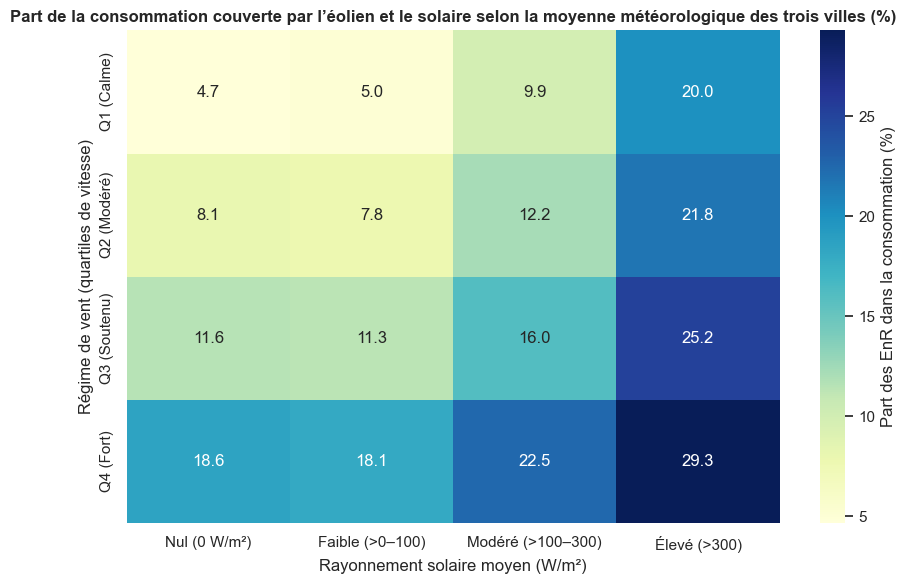

In [24]:
fig, ax = plt.subplots(figsize=(9, 6))
pivot_enr = df.pivot_table(index="q_vent", columns="q_sol", values="part_enr", aggfunc="mean", observed=False)

sns.heatmap(pivot_enr, annot=True, fmt=".1f", cmap="YlGnBu", ax=ax, cbar_kws={"label": "Part des EnR dans la consommation (%)"})
ax.set_title("Part de la consommation couverte par l’éolien et le solaire selon la moyenne météorologique des trois villes (%)", fontsize=12, fontweight="bold")
ax.set_xlabel("Rayonnement solaire moyen (W/m²)")
ax.set_ylabel("Régime de vent (quartiles de vitesse)")

plt.tight_layout()
plt.show()

### Ce qu’on voit
La part des EnR va de 4,7 % quand le vent est calme et le rayonnement nul à 29,3 % quand les deux sont élevés.

### Pourquoi
Le vent et le soleil favorisent les productions éolienne et solaire.

### Lien avec la question
La météo est associée à des parts EnR différentes, et donc à la charge résiduelle. La heatmap ne prouve pas de lien causal et repose sur trois villes.

# Conclusion générale

Les données RTE et Open-Meteo montrent que le vent est associé à la production éolienne, le rayonnement à la production solaire, et le froid à une consommation plus élevée. La part moyenne des EnR est aussi plus forte quand le vent et le rayonnement sont élevés. Ces résultats décrivent des liens, pas des causes.

## Quelques chiffres
La consommation moyenne est de 51,0 GW. L’éolien produit en moyenne 5,0 GW et le solaire 2,35 GW. La charge résiduelle moyenne est de 43,7 GW. Les corrélations vent-éolien et rayonnement-solaire sont respectivement de 0,796 et 0,868. La part des EnR varie de 4,7 % à 29,3 % entre les conditions extrêmes de la heatmap.

## Limites et suites possibles
La météo ne couvre que Brest, Paris et Marseille, et les moyennes horaires masquent les variations plus fines. Une suite pourrait ajouter des villes ou stations, utiliser un pas de temps plus court et tenir compte des saisons et des heures de la journée.